In [1]:
%load_ext autoreload
%autoreload 2


# I. RPM Dataset

## 1. RPM Test:

An ***RPM*** or **R**.**A**.**V**.**E**.**N** (**R**elational and **A**nalogical r**E**aso**N**ing) **P**rogressive **M**atrices is a classical psychometrique test for human fluide intelligence, this is the first RPM dataset to afford tree-structures annotations making a semantic link between visual perception and structural reasoning.

An **RPM** is mainly a 3X3 mtarix having the last (index = [2,2]) position is missing : 

<table>
    <tr>
        <td>PANEL 1</td>
        <td>PANEL 2</td>
        <td>PANEL 3</td>
    </tr>
    <tr>
        <td>PANEL 4</td>
        <td>PANEL 5</td>
        <td>PANEL 6</td>
    </tr>
    <tr>
        <td>PANEL 7</td>
        <td>PANEL 8</td>
        <td>PANEL 9</td>
    </tr>
</table>

Answer candidates: [A] [B] [C] [D] [E] [F] [G] [H]  (8 candidats)

## 2. RPM Dataset

RAVEN dataset is generated using the project [DhiaEddineSaidi/RAVEN](https://github.com/DhiaEddineSaidi/RAVEN) forked from the original [WellyZhang/RAVEN](https://github.com/WellyZhang/RAVEN) repo for the purposes of fixing bugs and versions.

### Output Files
The dataset files :  
```
dataset/
├── center_single/
│   ├── RAVEN_0_train.npz    ← Problem 0, split train
│   ├── RAVEN_0_train.xml    ← Annotations XML
│   ├── RAVEN_1_train.npz
│   ...
│   ├── RAVEN_N_val.npz      ← Split validation
│   ├── RAVEN_N_test.npz     ← Split test
├── distribute_four/
├── distribute_nine/
├── left_center_single_right_center_single/
├── up_center_single_down_center_single/
├── in_center_single_out_center_single/
└── in_distribute_four_out_center_single/ 
```

### NPZ File
Each npz file contains the following:

* 'image': a (16, 160, 160) array where all 16 figures in each problem are stacked on the first dimension. Note that first 8 figures compose the problem matrix and the last 8 figures are choices.
* 'target': the index of the correct answer in the answer set. Note that it starts from 0 and you should offset it by 8 if you want to retrieve it from the image array.
* 'structure': the tree structure annotation for the problem. It's serialized into a sequence using pre-order traversal.
* 'meta_matrix': similar to that in PGM. Detailed ordering could be found in ```src/dataset/const.py```.
* 'meta_target': bitwise-or of meta_matrix on all rows. 
* 'meta_structure': it's similar to meta_matrix. Detailed ordering is in ```src/dataset/const.py```.
### XML File
Each xml file contains the following:

* Context panels and choice panels: each Panel could be further decomposed into Struct, Component, Layout, and Entity.
  * Each layer comes with its name and id if necessary.
  * Layout has its own attributes, whose values are indices into the value set (see also ```src/dataset/const.py```), except Position. Position is a list of slots entities could occupy, denoted by center and width/height. 
  * Entity's attributes follow the same annotation. The bbox is retrieved from the Position array in its parent Layout and the real_bbox is the actual bounding box, denoted by center and width/height. The mask is encoded using the run-length encoding. To decode it, use the ```rle_decode``` function in ```src/dataset/api.py```.
* Rules: rules are divided into groups, each of which applies to the corresponding component with the same id number. 
  * ```attr``` could be ```Number/Position``` when the rule is ```Constant``` as these two attributes are deeply coupled.
  * When there is a rule on ```Number``` or ```Position```, we omit the rule on the other attribute, as it should be assumed **as is**, *i.e.*, following the rule on the other (could remain unchanged).
  * Therefore, each rule group has 4 rules.

## 3. RAVEN Structure
The structure of RAVEN is designed by associating each problem instance with a sentence derived from a stochastic image grammar [(A-SIG)](https://dash.harvard.edu/entities/publication/73120378-84d2-6bd4-e053-0100007fdf3b); specifically, the A-SIG serves as the representation for the RPM, and each RPM is a parse tree instantiated from the [(A-SIG)](https://dash.harvard.edu/entities/publication/73120378-84d2-6bd4-e053-0100007fdf3b). After [rules](#3-rpm-rules) are sampled, the grammer is prunned (trimmed down or reduced by ermoving extra unwanted parts).

Generated Panels consist of scenes. Each scene contains a structure composed of 1 or 2 components. Each component has 1 layout, and each layout contains 1 to 9 entities.

<div align="center">
  <img src="../assets/images/raven_structure.png" alt="Alt text" style="width: 65%;">
</div>

## 3.1. Attributes 
Each entity (geometrique Object) has 7 attributes, 5 rule-governing attributrs and 2 noise attributes, each rule-governing attribute goes over one of 4 [rules](#3-rpm-rules) : 

<table>
  <tr>
    <th>Attribute</th>
    <th>Possible values (encoded)</th>
    <th>Possible Values (real)</th>
    <th>Constraint type</th>
    <th>Description</th>
  </tr>
  <tr style="background-color: #fffec3ff;">
    <td>Number (RG)</td>
    <td>[0,1,2,3,4,5,6,7,8]</td>
    <td>[1,2,3,4,5,6,7,8,9]</td>
    <td>Layout</td>
    <td>The number of `Entity(ies)` in that `Layout`</td>
  </tr>
  <tr style="background-color: #fffec3ff;">
    <td>Position (RG)</td>
    <td colspan=2 style="font-size: small;">List[x: int , y: int , max_w:int , max_h:int] : 
        <ul>
            <li><div style='font-weight: bold'>center_single:</div>
            [[0.5, 0.5, 1, 1]]
            </li>
            <li> <div style='font-weight: bold'>distribute_four:</div>
            [[0.25, 0.25, 0.5, 0.5], [0.25, 0.75, 0.5, 0.5], </br>
             [0.75, 0.25, 0.5, 0.5], [0.75, 0.75, 0.5, 0.5]]
             </li>
            <li><div style='font-weight: bold'>distribute_nine: </div>
            [[0.16, 0.16, 0.33, 0.33], [0.16, 0.5, 0.33, 0.33], [0.16, 0.83, 0.33, 0.33], </br>
             [0.5, 0.16, 0.33, 0.33], [0.5, 0.5, 0.33, 0.33], [0.5, 0.83, 0.33, 0.33], </br>
             [0.83, 0.16, 0.33, 0.33], [0.83, 0.5, 0.33, 0.33], [0.83, 0.83, 0.33, 0.33]]
             </li>
            <li><div style='font-weight: bold'>in_center_single_out_center_single:</div>
                <ul>
                    <li><div style='font-weight: bold'>Out_Center_Single:</div>
                    [[0.5, 0.5, 1, 1]]
                    </li>
                    <li><div style='font-weight: bold'>In_Center_Single:</div>
                    [[0.5, 0.5, 0.33, 0.33]]
                    </li>
                </ul>
            </li>
            <li><div style='font-weight: bold'>in_ditribute_four_out_center_single</div>
                <ul>
                    <li><div style='font-weight: bold'>Out_Center_Single:</div>
                    [[0.5, 0.5, 1, 1]]
                    </li>
                    <li><div style='font-weight: bold'>In_Distribute_Four:</div>
                    [[0.42, 0.42, 0.15, 0.15], [0.42, 0.58, 0.15, 0.15],</br>
                     [0.58, 0.42, 0.15, 0.15], [0.58, 0.58, 0.15, 0.15]]
                    </li>
                </ul>
            </li>
            <li><div style='font-weight: bold'>left_center_single_right_center_single</div>
                <ul>
                    <li><div style='font-weight: bold'>Left_Center_Single:</div>
                    [[0.5, 0.25, 0.5, 0.5]]
                    </li>
                    <li><div style='font-weight: bold'>Right_Center_Single:</div>
                    [[0.5, 0.75, 0.5, 0.5]]
                    </li>
                </ul>
            </li>
            <li><div style='font-weight: bold'>up_center_single_down_center_single</div>
                <ul>
                    <li><div style='font-weight: bold'>Up_Center_Single:</div>
                    [[0.25, 0.5, 0.5, 0.5]]
                    </li>
                    <li><div style='font-weight: bold'>Down_Center_Single:</div>
                    [[0.75, 0.5, 0.5, 0.5]]
                    </li>
                </ul>
            </li>
        </ul>
    </td>
    <td>Layout</td>
    <td>The possible positions of the `Enity(ies)` in the panel based on coordinate system (with max_x and max_h for rendering purposes)</td>
  </tr>
  <tr style="background-color: #dcffb4ff;">
    <td>Type (RG)</td>
    <td>[0,1,2,3,4,5]</td>
    <td>['none','triangle','square','pentagon','hexagon','circle']</td>
    <td>Entity</td>
    <td> The geometrique shape of the `Entity`</td>
  </tr>
  <tr style="background-color: #dcffb4ff;">
    <td>Size (RG)</td>
    <td>[0,1,2,3,4,5]</td>
    <td>[0.4, 0.5, 0.6, 0.7, 0.8, 0.9]</td>
    <td>Entity</td>
    <td>The size of the `Entity`</td>
  </tr>
  <tr style="background-color: #dcffb4ff;">
    <td>Color (RG)</td>
    <td>[0,1,2,3,4,5,6,7,8,9]</td>
    <td>[255, 224, 196, 168, 140, 112, 84, 56, 28, 0]</td>
    <td>Entity</td>
    <td>The color of the `Entity` in the gray scale </td>
  </tr>
  <tr>
    <td>Uniformity (N)</td>
    <td>[0,1,2,3]</td>
    <td>[False, False, False, True]</td>
    <td>Layout</td>
    <td>wether all the `Entity` shares the same values within that `Layout`</td>
  </tr>
  <tr>
    <td>Angle (N)</td>
    <td>[0,1,2,3,4,5,6,7]</td>
    <td>[-135, -90, -45, 0, 45, 90, 135, 180]  </td>
    <td>Entity</td>
    <td>The rotation angle of the `Entity`</td>
  </tr>
</table>
*  (RG) : Rule Governed
** (N)  : Noise
</br>
<table style="border-collapse: collapse;">
  <tr>
    <td style="background-color: #fffec3ff; border: none;">Layout attribute</td>
  </tr>
  <tr>
    <td style="background-color: #dcffb4ff; border: none;">Entity attribute</td>
  </tr>
</table>


## 3.2. RPM Rules

Rules in RPM problems are governing rule-governing attributes and they are applied row-wise, we have 4 types of rules :
<table>
<th>Rule Type</th>
<th>Rule Description</th>
<tr>
    <td>Constant</td>
    <td>The attribute has the same value all over the row panels</td>
</tr>
<tr>
    <td>Progression</td>
    <td>The attribute evolve with a constatnt step (+1, +2, -1, -2) all over the row panels</td>
</tr>
<tr>
    <td>Arithmetic</td>
    <td> Panel_3 = Pane_l ± Panel_2 </td>
</tr>
<tr>
    <td>Distribute Three</td>
    <td>The attribute takes 3 distinct values from its possible values, distributed over the three panels of the row</td>
</tr>
</table>

in totla we have 8 rules: 
1. constant : same value of the attribute
2. progression: with step= +1
3. progression: with step= +2
4. progression: with step= -1
5. progression: with step= -2
6. Arithmetic: Panel_3= Panel_1 + Panel_2
7. Arithmetic: Panel_3= Panel_1 - Panel_2
8. Distribute Three : 3 distinct values of the attribute

### 3.2.1 ***Position*** attribute with Rule types that uses numerical operations
`Progression` and `Arithmetic` Rule types uses numerical operations like addition `+` and substraction `-`. Except the attribute `Position` other attributes are numerical, even if they are not in reality but transformed with a propper encoding. 
The `Position` attribute is not numerical so the addition `+` and substraction `-` operations are not possible. To resolve this RAVEN authors gave these rules another meaning for the `Position` attribute case: 
* Rule type `Progression` : means moving in Layout slots in order
    - Examples : 
        * [distribute_four](../../data/raven/distribute_four/RAVEN_10042_train.xml) ![position progression in 2x2 matrix](../assets/images/position_progression_in_distribute_four.png)
        * [distribute_nine](../../data/raven/distribute_nine/RAVEN_10001_train.xml) ![position progression in 3x3 matrix](../assets/images/position_progression_in_distribute_nine.png)
        * [in_distribute_four_out_center_single](../../data/raven/in_distribute_four_out_center_single/RAVEN_10030_train.xml)
* Rule type `Arithmetic` : the addition `+` means SET_UNION and the substraction `-` means SET_DIFF
    - Examples : 
        * [distribute_four](../../data/raven/distribute_four/RAVEN_10005_train.xml) ***Panel_3 = Panel_1 - Panel_2*** 
        * [distribute_nine](../../data/raven/distribute_nine/RAVEN_25_train.xml) ***Panel_3 = Panel_1 + Panel_2*** 
        * [in_distribute_four_out_center_single](../../data/raven/in_distribute_four_out_center_single/RAVEN_0_train.xml) ***Panel_3 = Panel_1 + Panel_2***


# II. Data Exploration

To visualize an RPM problem we introduce the ***Oracle*** which is basically a matplotlib based helper functions used to see a problem and make a challenge.
The Oracle uses a couple of utility functions (**readers**) to read and parse the RPM problem descriptor files (xml and npz).

<div align="center">
  <img src="../assets/images/the_oracle_matrix_movie.png" alt="Alt text" style="width: 50%;">
</div>

## 1. watching a problem

Problem dataset: raven-100
Problem configuration: in_distribute_four_out_center_single
Problem id: 63
Problem split: train

The correct answer is: 2


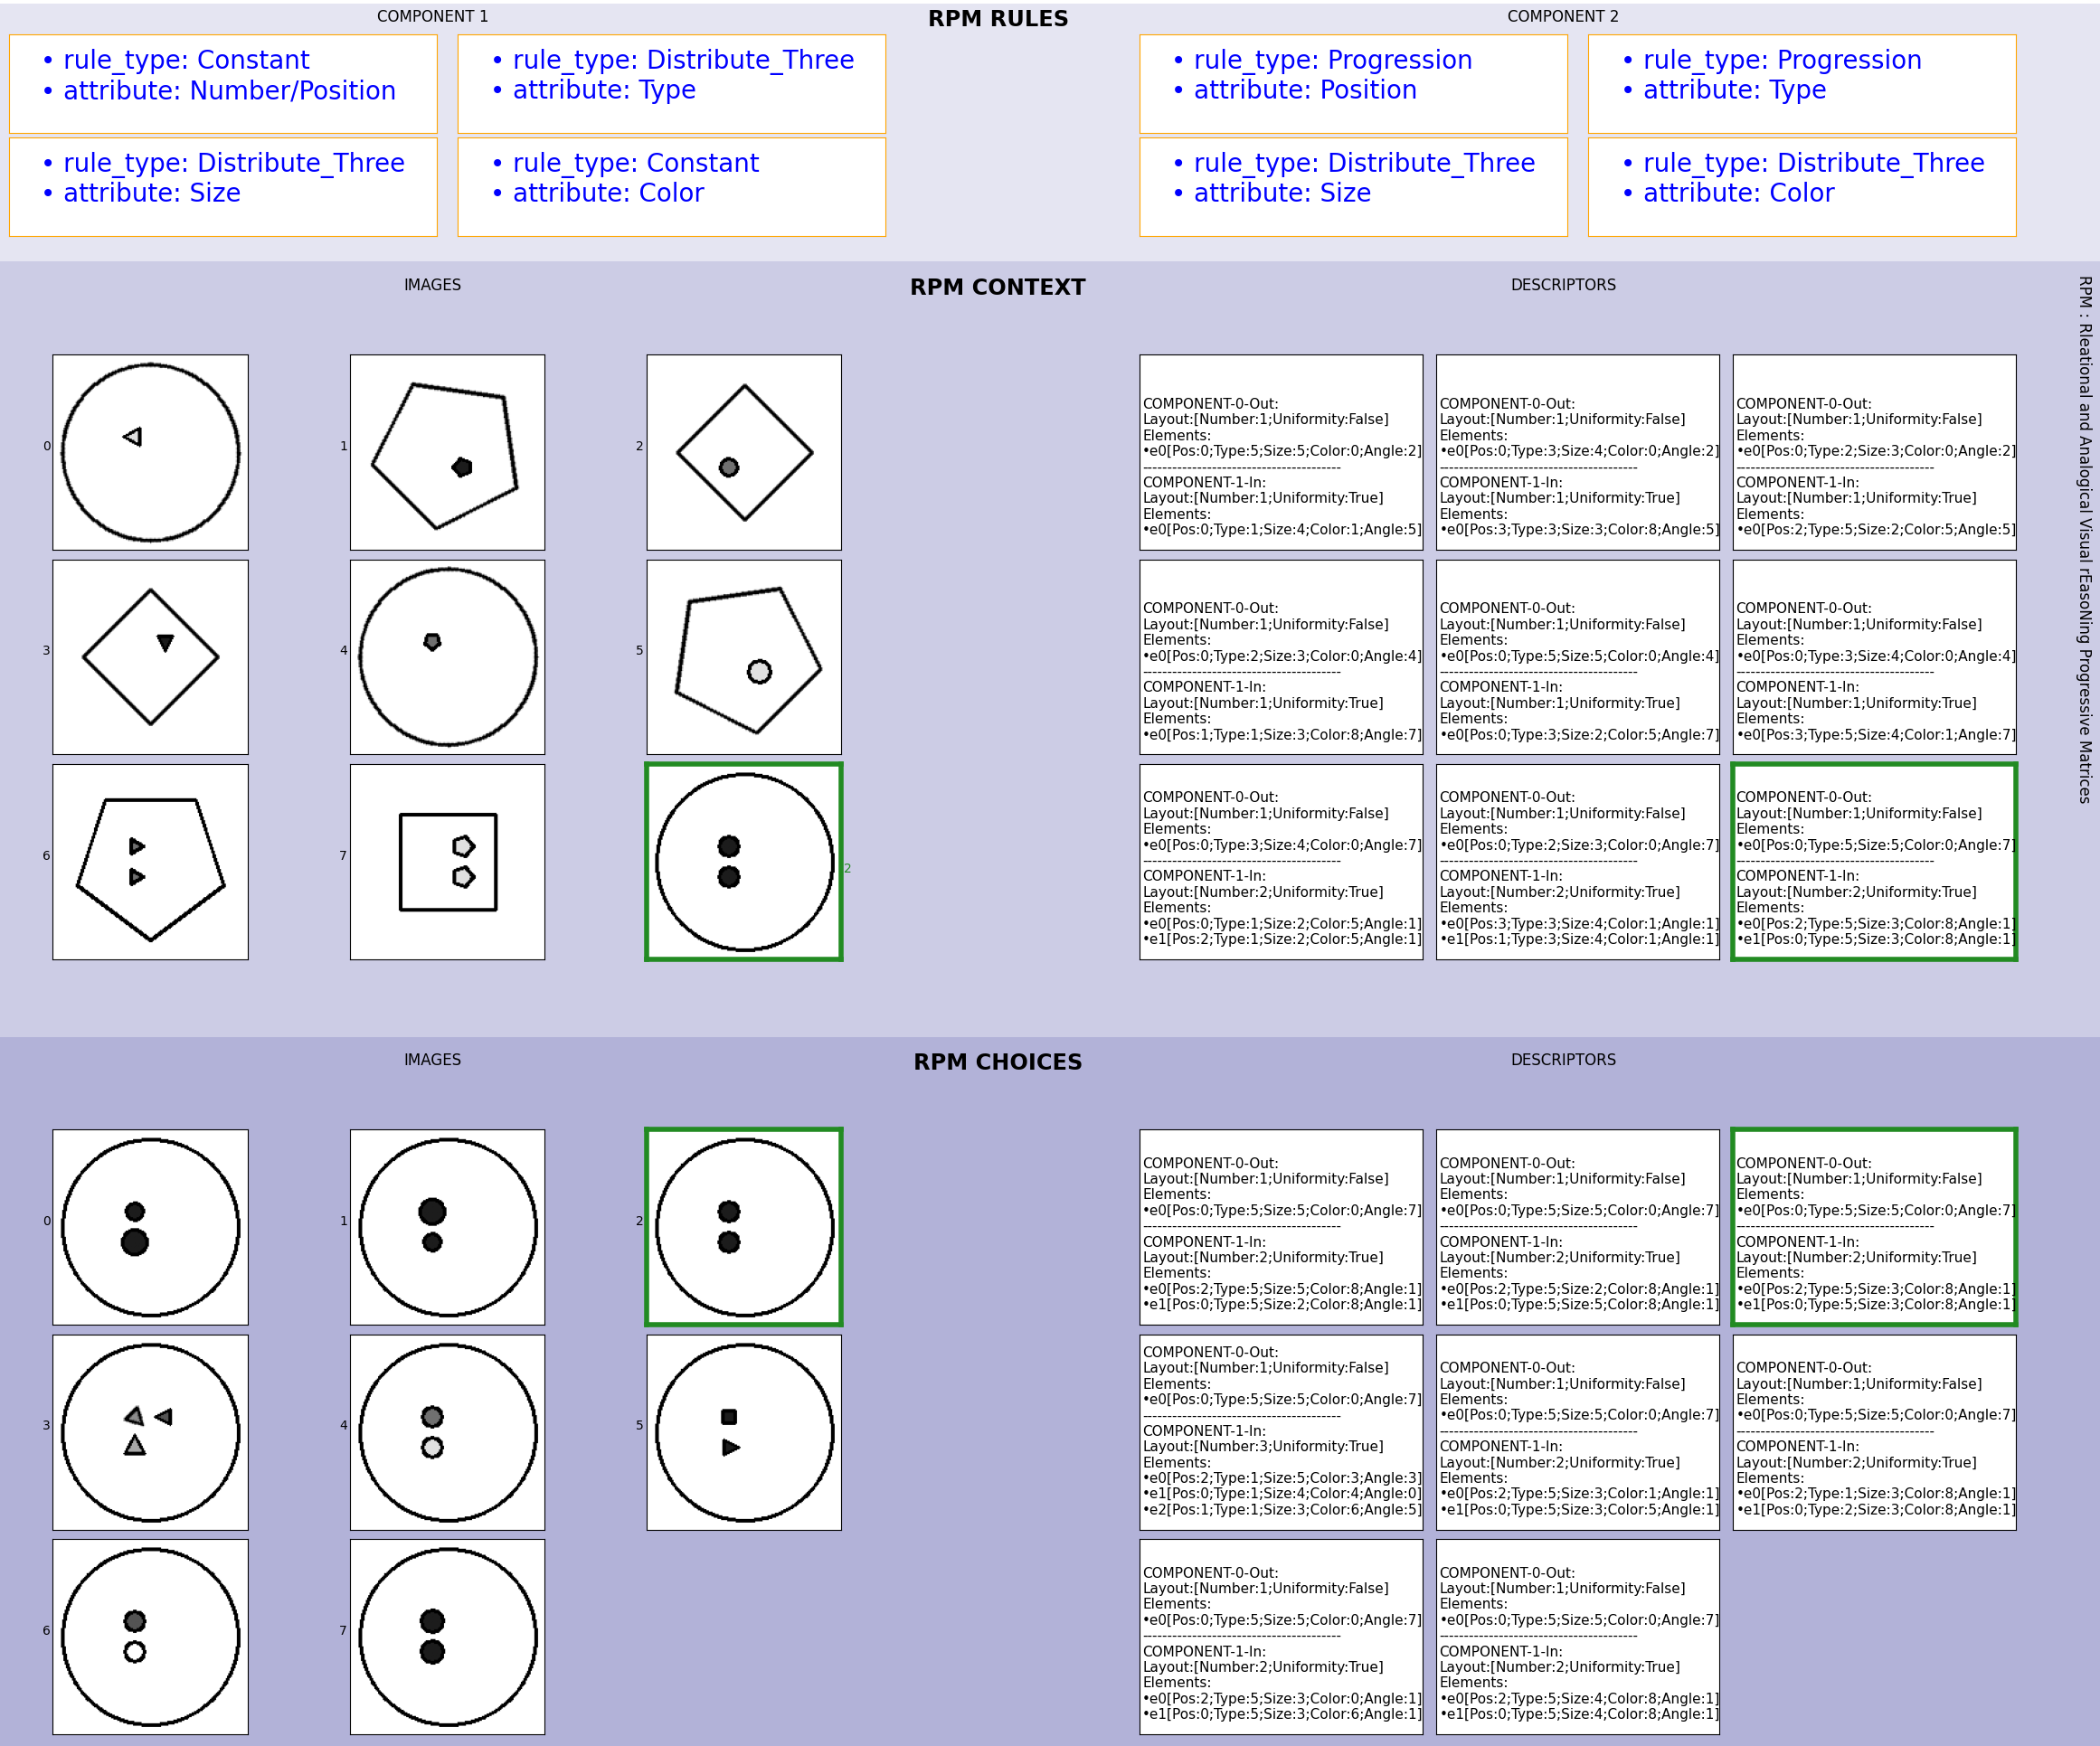

In [15]:
from hri_gnn.utils.data import readers
from hri_gnn.visualization import oracle
from hri_gnn.config.const import Configuration

problem = readers.read_random_problem(Configuration.IN_DISTRIBUTE_FOUR_OUT_CENTER_SINGLE.value)
#problem = readers.read_random_problem()
oracle.watch_problem(problem, show_answer=True)


## 2. Challenging the oracle

<div align="center">
  <img src="../assets/images/neo_wants_to_play_matrix_movie.png" alt="Alt text">
</div>

***You can challaenge the Oracle by picking an answer and see what happens***

Problem dataset: raven-100
Problem configuration: in_distribute_four_out_center_single
Problem id: 63
Problem split: train

Your answer is : 7
Try again, hard luck !!......


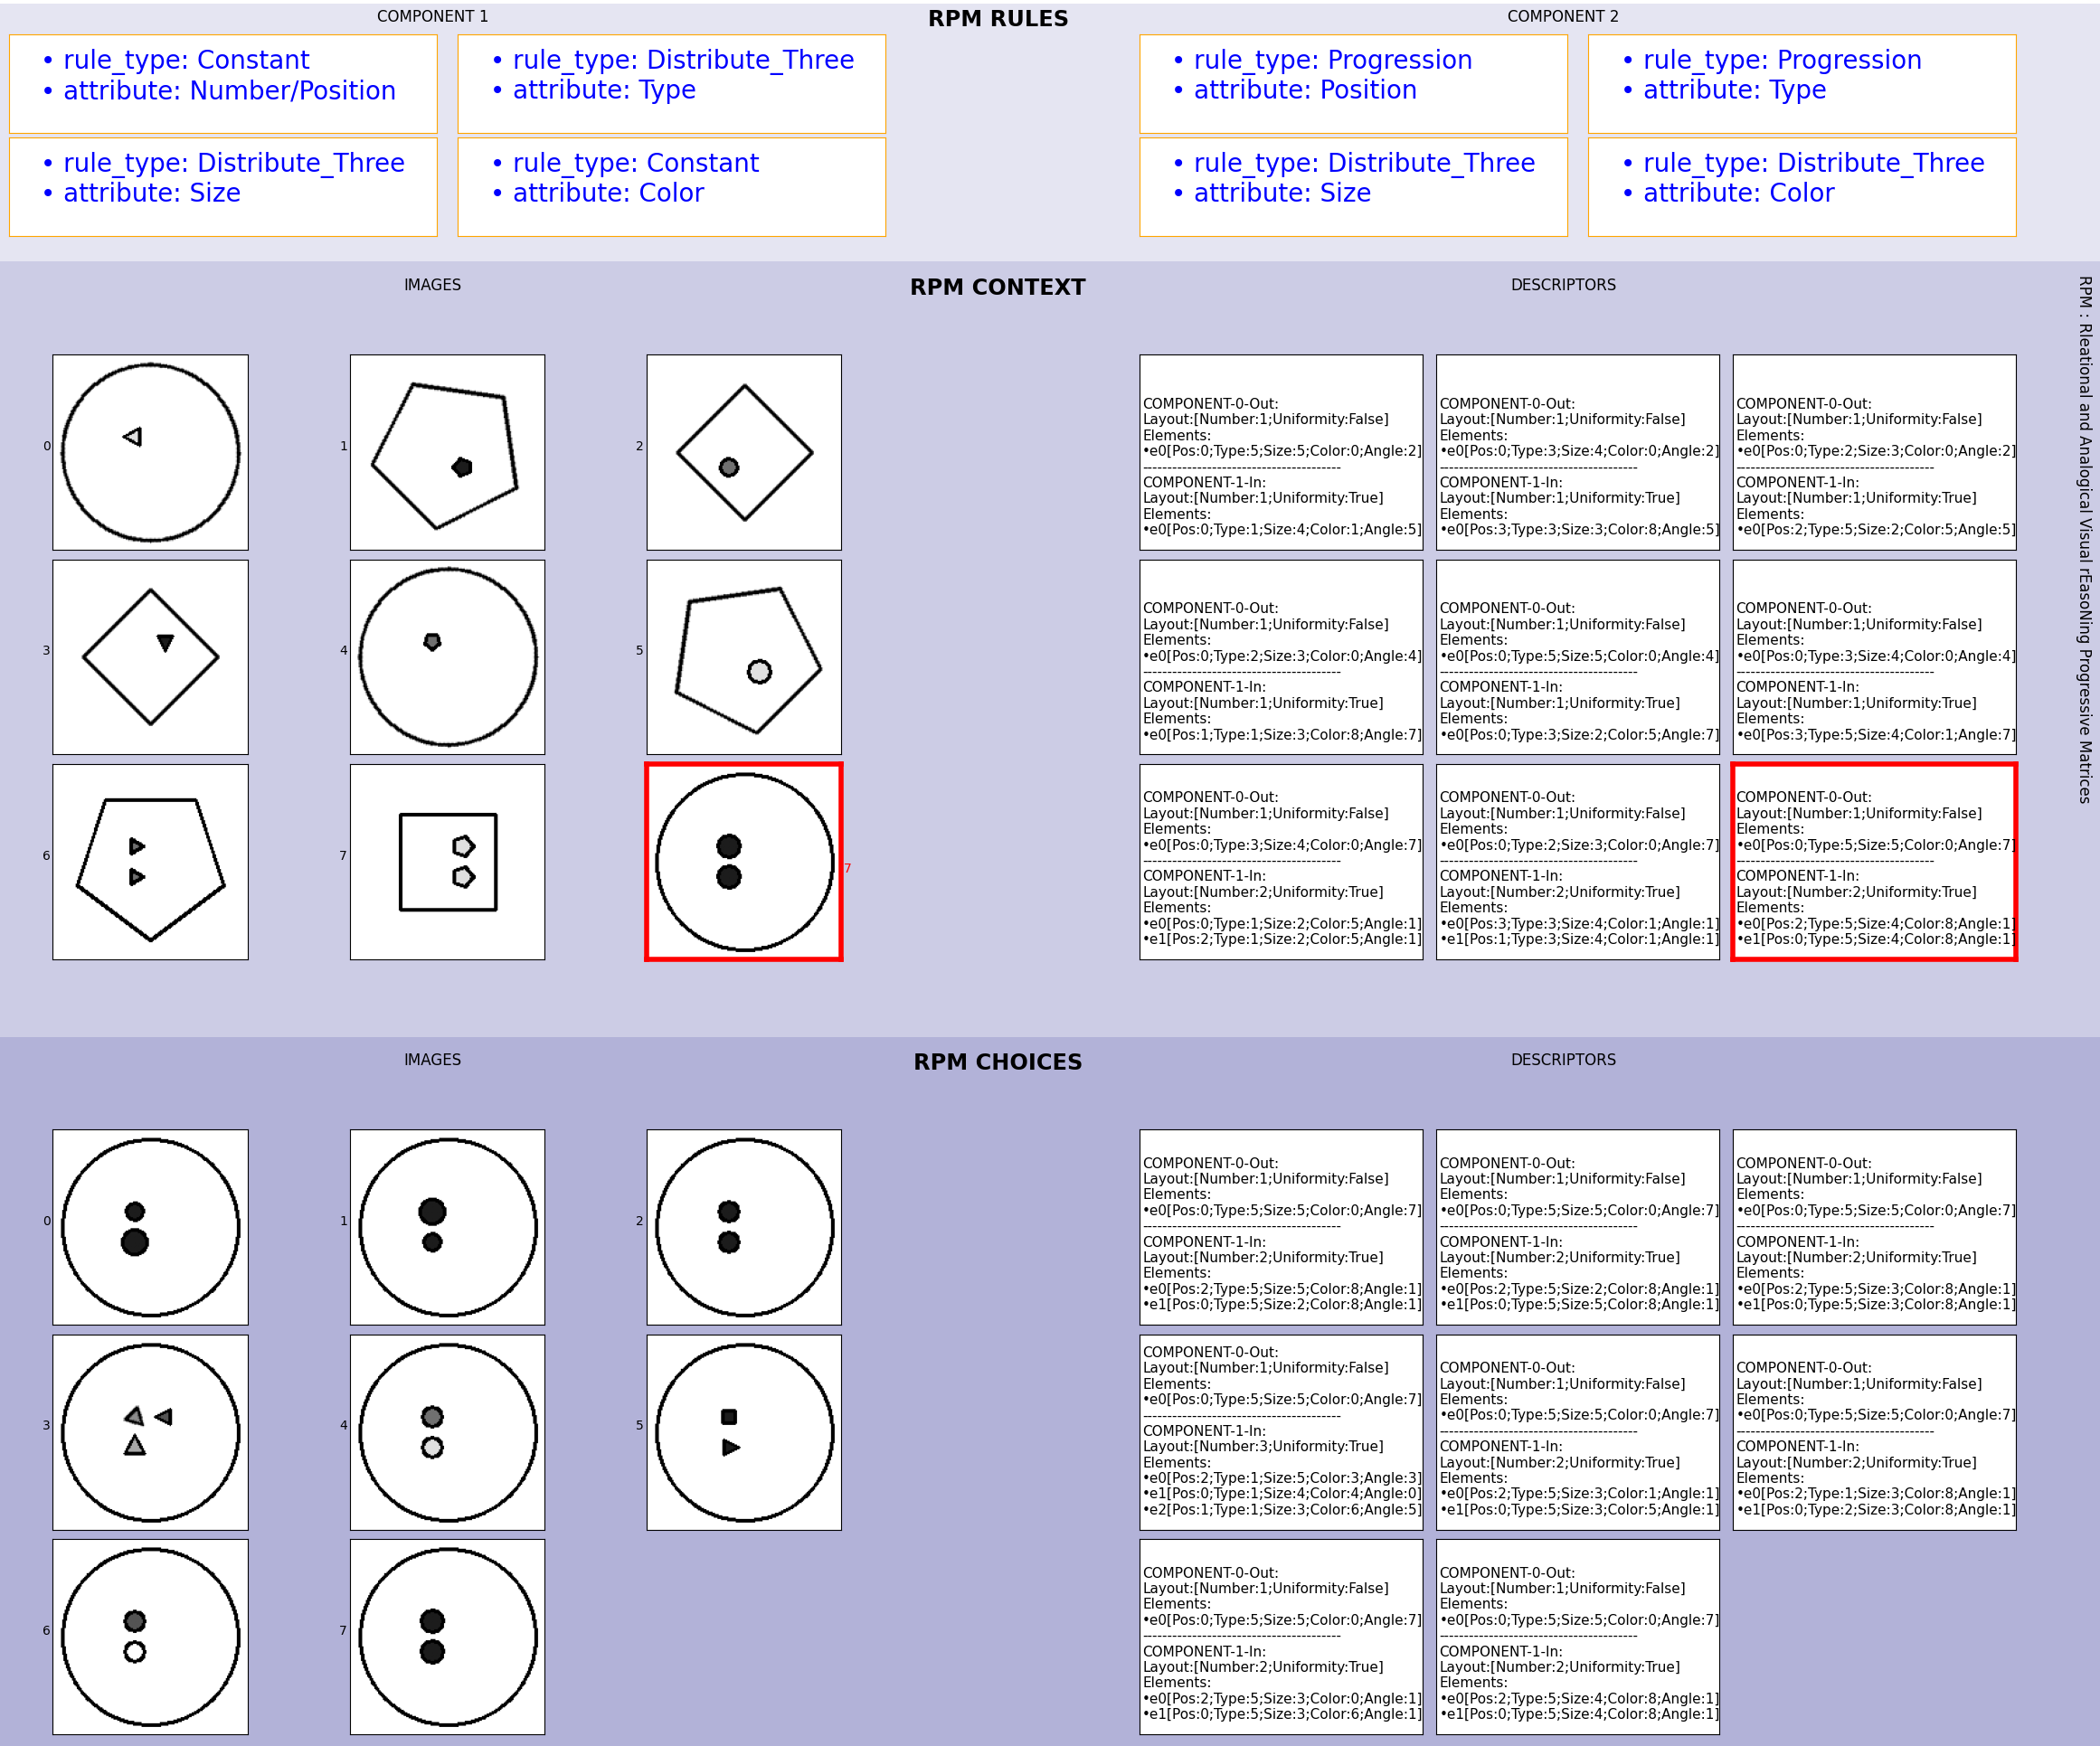

In [16]:
from hri_gnn.visualization import oracle

oracle.watch_problem(problem, challenge=True, show_answer=False)


## 3. Plot a panel 

### 3.1 Random

for reproducebility purposes you can fix th optional `seed` of any random method

#### 3.1.1 Randomly selected from all problems



COMPONENT-0-Up:
Layout:[Number:1;Uniformity:False]
Elements:
•e0[Pos:0;Type:5;Size:4;Color:6;Angle:3]
----------------------------------------
COMPONENT-1-Down:
Layout:[Number:1;Uniformity:False]
Elements:
•e0[Pos:0;Type:5;Size:3;Color:4;Angle:7]



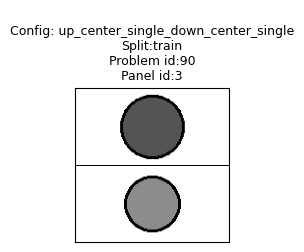

In [11]:
from hri_gnn.utils.data import readers
from hri_gnn.visualization import oracle

random_problem = readers.read_random_problem()
oracle.plot_random_panel(random_problem)

#### 3.1.2 Randomly selected from all problems of a specific config 

COMPONENT-0-Grid:
Layout:[Number:1;Uniformity:False]
Elements:
•e0[Pos:2;Type:4;Size:4;Color:9;Angle:6]



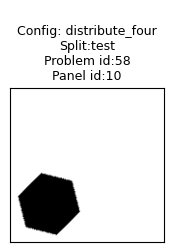

In [14]:
from hri_gnn.config.const import Configuration

random_problem = readers.read_random_problem(Configuration.DISTRIBUTE_FOUR.value)
oracle.plot_random_panel(random_problem)

# III. Data Preparation

# 1. Data augmentation (Cropping panel images)

* In order to enable the CNN model with better perception capabilities to learn attributes (Type, Size, Color, Angle) we intend to make a data augmentation by cropping each element producing several seperate images for each panel.

* We need Bounding Boxes('bbox' from the xml file) to separate the elements from their panels.

* For the special case of `Out_In` structures like, we need to erase the inner shapes from the outer ones after cropping the panel image.

* Cropping results : image with different sizes, so resising results is crucial.

* All images must be tensors.

PS : 
* original panel images are with shape (160,160) (W, H)
* PyTorch prefered default shape format is (C, H, W)
* matplotlib (numpy based) prefered shape is (C, W, H)

# 2. Custom Dataset & DataLoader

In order to prepare the data for training on our `RavenDataset` produces:
* For perception with CNN : 
    * Crops (entityt tensor images [1x80x80]) as `features`
    * Vector-Attributes (Type, Size, Color, Angle) as `labels` 
* For Graph representation with GNN :
    * problem_indices & panel indices : for regrouping crops (making a graph per panel per problem)
    * Vector-Attributes (Type, Size, Color, Angle) as `labels` , which will be used for the `nodes`
    * bboxes for the spacial relationships between crops, which will bes used for the `edges` 

In [ ]:
from torch.utils.data import DataLoader

from hri_gnn.config.const import Configuration
from hri_gnn.datasets import  RavenDataset , gnn_flat_collate


raven_dataset = RavenDataset(dataset="raven-100", split="test",limit_per_config=10)
mon_dataloader = DataLoader(
    raven_dataset, 
    batch_size=16,               # Number of RAVEN problems per batch
    shuffle=True,                # Shuffling for the train purposes
    collate_fn=gnn_flat_collate  # for flattening the batch
)

# for batch_idx, batch in enumerate(mon_dataloader):
#         # On dépaquette ce que renvoie le gnn_flat_collate
#         flat_crops, flat_attrs, flat_bboxes, flat_panel_indices, flat_batch_indices = batch

flat_crops, flat_attrs, flat_bboxes, flat_panel_indices, flat_batch_indices =next(iter(mon_dataloader))


ImportError: cannot import name 'get_dataset' from partially initialized module 'hri_gnn.utils.data' (most likely due to a circular import) (C:\Users\dhias\workspaces\these\HRI-GNN\src\hri_gnn\utils\data\__init__.py)

In [5]:
flat_batch_indices

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [17]:
flat_panel_indices.unique()

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])

In [7]:
flat_bboxes.shape

torch.Size([45, 4])

In [8]:
flat_attrs.shape

torch.Size([45, 4])

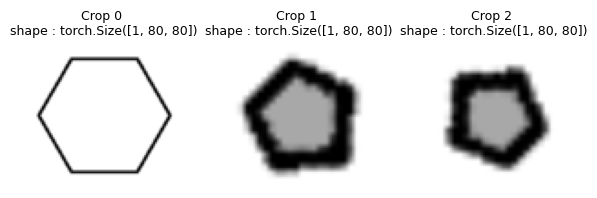

In [13]:
from hri_gnn.visualization import oracle
oracle.plot_crops(flat_crops[:3],)
